In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [2]:
# sklearn diabetes 데이터 로드 (DataFrame)
# feature: age, sex, bmi, bp, s1~s6 (표준화된 값)
# bmi: 체질량지수 — 단변수 회귀에서 쓸 피처
# target: 당뇨 진행 점수 (연속값, 1년 후 질병 진행 정도)
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

print(df.head())
print("컬럼:", df.columns.tolist())
print("행 개수:", len(df))

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  
컬럼: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']
행 개수: 442


In [3]:
# 단변수 선형회귀: X = BMI만, y = target(당뇨 진행 점수)
X = df[["bmi"]]
y = df["target"]

# 학습/테스트 분리 (8:2)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (353, 1)
X_test shape: (89, 1)


In [4]:
# 선형회귀 학습
regr = LinearRegression()
regr.fit(X_train, y_train)

# coef_: 기울기 β, intercept_: 절편 α
print("coef_ (기울기):", regr.coef_)
print("intercept_ (절편):", regr.intercept_)

# 해석 (session11 톤)
print(f"BMI 1 단위 증가 시 당뇨 진행 점수 약 {regr.coef_[0]:.2f} 변화")
print(f"BMI가 0일 때 예측값(절편) 약 {regr.intercept_:.2f}")
print(f"예측식: ŷ = {regr.coef_[0]:.2f} · BMI + {regr.intercept_:.2f}")

coef_ (기울기): [977.74040067]
intercept_ (절편): 151.66780594915235
BMI 1 단위 증가 시 당뇨 진행 점수 약 977.74 변화
BMI가 0일 때 예측값(절편) 약 151.67
예측식: ŷ = 977.74 · BMI + 151.67


In [5]:
# train/test 예측
y_train_pred = regr.predict(X_train)
y_test_pred = regr.predict(X_test)

# sklearn r2_score
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)
print(f"Train R²: {r2_train:.4f}")
print(f"Test  R²: {r2_test:.4f}")

Train R²: 0.3632
Test  R²: 0.2513


In [6]:
# R² = 1 - RSS/TSS 직접 검증 (test 기준)
# RSS: 예측과 실제 차의 제곱합
# TSS: 평균과 실제 차의 제곱합
rss = np.sum((y_test - y_test_pred) ** 2)
tss = np.sum((y_test - y_test.mean()) ** 2)
r2_manual = 1 - rss / tss

print(f"RSS: {rss:.4f}")
print(f"TSS: {tss:.4f}")
print(f"수동 계산 R² = 1 - RSS/TSS: {r2_manual:.4f}")
print(f"r2_score 결과:              {r2_test:.4f}")
print("일치 여부:", np.isclose(r2_manual, r2_test))

RSS: 355094.7786
TSS: 474278.3596
수동 계산 R² = 1 - RSS/TSS: 0.2513
r2_score 결과:              0.2513
일치 여부: True


C:\Users\dmsrh\AppData\Local\Temp\ipykernel_9028\3850197289.py:16: UserWarning: Glyph 45817 (\N{HANGUL SYLLABLE DANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\dmsrh\AppData\Local\Temp\ipykernel_9028\3850197289.py:16: UserWarning: Glyph 45544 (\N{HANGUL SYLLABLE NYO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\dmsrh\AppData\Local\Temp\ipykernel_9028\3850197289.py:16: UserWarning: Glyph 51652 (\N{HANGUL SYLLABLE JIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\dmsrh\AppData\Local\Temp\ipykernel_9028\3850197289.py:16: UserWarning: Glyph 54665 (\N{HANGUL SYLLABLE HAENG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\dmsrh\AppData\Local\Temp\ipykernel_9028\3850197289.py:16: UserWarning: Glyph 51216 (\N{HANGUL SYLLABLE JEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\dmsrh\AppData\Local\Temp\ipykernel_9028\3850197289.py:16: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from f

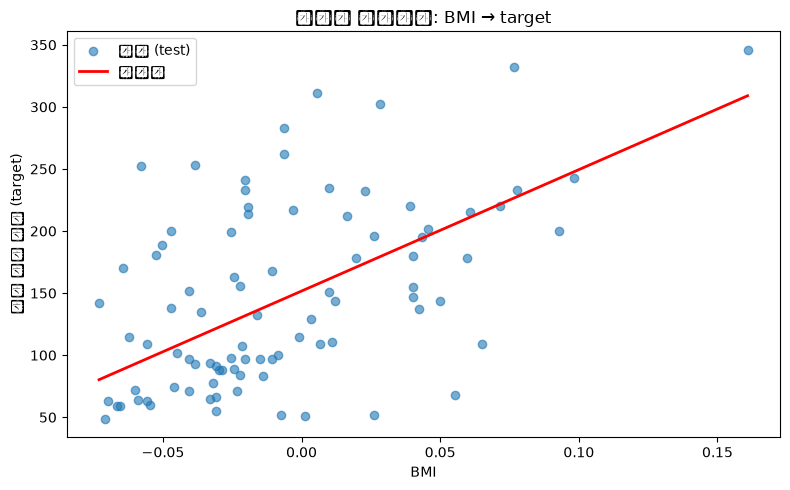

In [7]:
# 산점도(실제 BMI vs target) + 회귀선
plt.figure(figsize=(8, 5))
plt.scatter(X_test["bmi"], y_test, alpha=0.6, label="실제 (test)")

# 회귀선: BMI 정렬 후 예측값 연결
bmi_line = pd.DataFrame(
    {"bmi": np.linspace(X_test["bmi"].min(), X_test["bmi"].max(), 100)}
)
y_line = regr.predict(bmi_line)
plt.plot(bmi_line["bmi"], y_line, color="red", linewidth=2, label="회귀선")

plt.xlabel("BMI")
plt.ylabel("당뇨 진행 점수 (target)")
plt.title("단변수 선형회귀: BMI → target")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
# (선택) 전체 feature 다중 선형회귀 — session10 연결
X_all = df.drop(columns=["target"])
X_all_train, X_all_test, y_all_train, y_all_test = train_test_split(
    X_all, y, test_size=0.2, random_state=1
)

regr_multi = LinearRegression()
regr_multi.fit(X_all_train, y_all_train)
r2_multi_test = r2_score(y_all_test, regr_multi.predict(X_all_test))

print(f"단변수(BMI만) Test R²: {r2_test:.4f}")
print(f"다중(전체 feature) Test R²: {r2_multi_test:.4f}")
print("→ feature를 더 쓰면 보통 Test R²가 올라감")

단변수(BMI만) Test R²: 0.2513
다중(전체 feature) Test R²: 0.4384
→ feature를 더 쓰면 보통 Test R²가 올라감
